In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score
)

import torch

In [2]:
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

NumPy: 2.4.6
Pandas: 2.2.3
PyTorch: 2.14.1+cpu
Device: cpu


In [3]:
ENSEMBLE_SIZE = 3
NUM_CLASSES = 10
NUM_SAMPLES = 1000

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("Configuration initialized.")
print("Ensemble members:", ENSEMBLE_SIZE)
print("Classes:", NUM_CLASSES)
print("Samples:", NUM_SAMPLES)

Configuration initialized.
Ensemble members: 3
Classes: 10
Samples: 1000


In [4]:
ground_truth = np.random.randint(
    0,
    NUM_CLASSES,
    size=NUM_SAMPLES
)

print("Ground truth shape:", ground_truth.shape)
print("First 10 labels:", ground_truth[:10])

Ground truth shape: (1000,)
First 10 labels: [6 3 7 4 6 9 2 6 7 4]


In [5]:
synthetic_predictions = np.random.rand(
    ENSEMBLE_SIZE,
    NUM_SAMPLES,
    NUM_CLASSES
)

synthetic_predictions = (
    synthetic_predictions /
    synthetic_predictions.sum(axis=2, keepdims=True)
)

print("Prediction shape:", synthetic_predictions.shape)

Prediction shape: (3, 1000, 10)


In [6]:
probability_sums = synthetic_predictions.sum(axis=2)

print("First 5 probability sums:")
print(probability_sums[:, :5])

print("All probabilities valid:",
      np.all(synthetic_predictions >= 0) and
      np.all(synthetic_predictions <= 1))

print("All distributions sum to 1:",
      np.allclose(probability_sums, 1.0))

First 5 probability sums:
[[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]
All probabilities valid: True
All distributions sum to 1: True


In [7]:
predicted_classes = np.argmax(
    synthetic_predictions,
    axis=2
)

print("Predicted classes shape:", predicted_classes.shape)

Predicted classes shape: (3, 1000)


In [8]:
correctness = (predicted_classes == ground_truth)

print("Correctness shape:", correctness.shape)
print("First 10 predictions of model 1:")
print(predicted_classes[0, :10])

print("First 10 correctness values:")
print(correctness[0, :10])

Correctness shape: (3, 1000)
First 10 predictions of model 1:
[4 4 7 2 9 2 4 8 1 6]
First 10 correctness values:
[False False  True False False False False False False False]


In [9]:
print("Ground truth:", ground_truth.shape)
print("Probabilities:", synthetic_predictions.shape)
print("Predictions:", predicted_classes.shape)
print("Correctness:", correctness.shape)

for i in range(ENSEMBLE_SIZE):
    accuracy = np.mean(correctness[i]) * 100
    print(f"Model {i + 1} Accuracy: {accuracy:.2f}%")

Ground truth: (1000,)
Probabilities: (3, 1000, 10)
Predictions: (3, 1000)
Correctness: (3, 1000)
Model 1 Accuracy: 10.50%
Model 2 Accuracy: 10.40%
Model 3 Accuracy: 9.30%


In [10]:
def calculate_entropy(predictions):
    predictions = np.clip(predictions, 1e-12, 1.0)

    entropy = -np.sum(
        predictions * np.log(predictions),
        axis=-1
    )

    return entropy

In [11]:
individual_entropy = calculate_entropy(
    synthetic_predictions
)

print("Entropy shape:", individual_entropy.shape)
print("First 5 entropy values of model 1:")
print(individual_entropy[0, :5])

Entropy shape: (3, 1000)
First 5 entropy values of model 1:
[2.09594422 1.88856154 2.16235097 2.14319215 2.0597019 ]


In [12]:
confident_prediction = np.array([
    [1.0, 0.0, 0.0]
])

uncertain_prediction = np.array([
    [1/3, 1/3, 1/3]
])

confident_entropy = calculate_entropy(
    confident_prediction
)

uncertain_entropy = calculate_entropy(
    uncertain_prediction
)

print("Confident entropy:", confident_entropy[0])
print("Uncertain entropy:", uncertain_entropy[0])

assert np.isclose(confident_entropy[0], 0.0)
assert np.isclose(uncertain_entropy[0], np.log(3))

print("All tests passed!")

Confident entropy: 5.526204223185709e-11
Uncertain entropy: 1.0986122886681096
All tests passed!


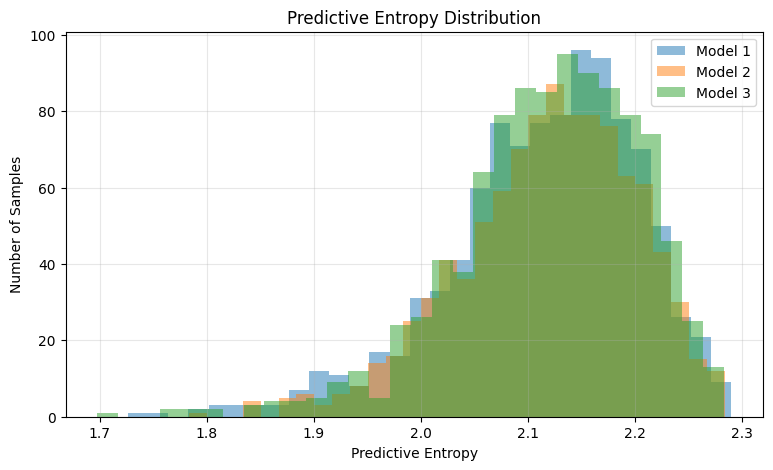

In [13]:
plt.figure(figsize=(9, 5))

for i in range(ENSEMBLE_SIZE):
    plt.hist(
        individual_entropy[i],
        bins=30,
        alpha=0.5,
        label=f"Model {i + 1}"
    )

plt.xlabel("Predictive Entropy")
plt.ylabel("Number of Samples")
plt.title("Predictive Entropy Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
def calculate_variation_ratio(predicted_classes):
    sample_count = predicted_classes.shape[1]

    variation_ratios = []

    for sample in range(sample_count):
        predictions = predicted_classes[:, sample]

        class_counts = np.bincount(
            predictions,
            minlength=NUM_CLASSES
        )

        maximum_votes = np.max(class_counts)

        disagreement = 1 - (maximum_votes / ENSEMBLE_SIZE)

        variation_ratios.append(disagreement)

    return np.array(variation_ratios)

In [15]:
variation_ratio = calculate_variation_ratio(
    predicted_classes
)

print("Variation Ratio shape:", variation_ratio.shape)
print("First 10 values:")
print(variation_ratio[:10])

Variation Ratio shape: (1000,)
First 10 values:
[0.33333333 0.66666667 0.33333333 0.33333333 0.33333333 0.66666667
 0.66666667 0.33333333 0.33333333 0.66666667]


In [16]:
test_predictions = np.array([
    [2, 2, 2],
    [2, 2, 3],
    [2, 3, 4]
])

test_disagreement = calculate_variation_ratio(
    test_predictions
)

print("Disagreement:", test_disagreement)

assert np.isclose(test_disagreement[0], 0.0)
assert np.isclose(test_disagreement[1], 1/3)
assert np.isclose(test_disagreement[2], 2/3)

print("All tests passed!")

Disagreement: [0.         0.33333333 0.66666667]
All tests passed!


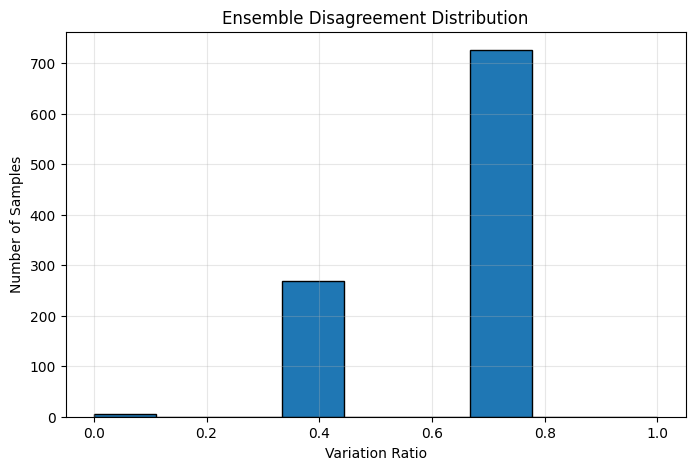

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(
    variation_ratio,
    bins=np.linspace(0, 1, 10),
    edgecolor="black"
)

plt.xlabel("Variation Ratio")
plt.ylabel("Number of Samples")
plt.title("Ensemble Disagreement Distribution")
plt.grid(alpha=0.3)

plt.show()

In [18]:
def calculate_jsd(predictions):
    predictions = np.clip(predictions, 1e-12, 1.0)

    mean_predictions = np.mean(
        predictions,
        axis=0
    )

    mean_predictions = np.clip(
        mean_predictions,
        1e-12,
        1.0
    )

    kl_divergence = np.sum(
        predictions * np.log(
            predictions / mean_predictions[np.newaxis, :, :]
        ),
        axis=2
    )

    jsd = np.mean(kl_divergence, axis=0)

    return jsd

In [19]:
jsd_scores = calculate_jsd(
    synthetic_predictions
)

print("JSD shape:", jsd_scores.shape)
print("First 10 JSD scores:")
print(jsd_scores[:10])

JSD shape: (1000,)
First 10 JSD scores:
[0.1261772  0.2192525  0.12588064 0.12901852 0.11869399 0.12316646
 0.0596385  0.12540759 0.06038485 0.12865696]


In [20]:
identical_predictions = np.array([
    [[0.8, 0.2]],
    [[0.8, 0.2]],
    [[0.8, 0.2]]
])

different_predictions = np.array([
    [[0.9, 0.1]],
    [[0.1, 0.9]],
    [[0.9, 0.1]]
])

identical_jsd = calculate_jsd(identical_predictions)
different_jsd = calculate_jsd(different_predictions)

print("Identical predictions JSD:", identical_jsd[0])
print("Different predictions JSD:", different_jsd[0])

assert np.isclose(identical_jsd[0], 0.0)
assert different_jsd[0] > 0

print("All tests passed!")

Identical predictions JSD: -1.1102230246251565e-16
Different predictions JSD: 0.33207478810589236
All tests passed!


In [21]:
# Cell 21: Calculate Average Ensemble Probabilities

ensemble_probabilities = np.mean(
    synthetic_predictions,
    axis=0
)

print("Ensemble probability shape:", ensemble_probabilities.shape)


Ensemble probability shape: (1000, 10)


In [22]:
# Cell 22: Generate Ensemble Predictions

ensemble_predictions = np.argmax(
    ensemble_probabilities,
    axis=1
)

print("Predictions shape:", ensemble_predictions.shape)
print("First 10 predictions:", ensemble_predictions[:10])

Predictions shape: (1000,)
First 10 predictions: [5 4 5 2 9 5 3 8 1 2]


In [23]:
# Cell 23: Calculate Prediction Correctness

ensemble_correctness = (
    ensemble_predictions == ground_truth
)

accuracy = np.mean(ensemble_correctness) * 100

print("Correctness shape:", ensemble_correctness.shape)
print("Ensemble Accuracy:", accuracy, "%")

Correctness shape: (1000,)
Ensemble Accuracy: 9.6 %


In [24]:
# Cell 24: Generate Error Labels

error_labels = (~ensemble_correctness).astype(int)

print("First 20 error labels:", error_labels[:20])
print("Total incorrect:", np.sum(error_labels))
print("Total correct:", np.sum(ensemble_correctness))

First 20 error labels: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Total incorrect: 904
Total correct: 96


In [25]:
# Cell 25: Calculate Ensemble Predictive Entropy

ensemble_entropy = calculate_entropy(
    ensemble_probabilities
)

print("Ensemble entropy shape:", ensemble_entropy.shape)

Ensemble entropy shape: (1000,)


In [26]:
# Cell 26: Collect Uncertainty Scores

uncertainty_scores = {
    "Ensemble Entropy": ensemble_entropy,
    "Variation Ratio": variation_ratio,
    "Jensen-Shannon Divergence": jsd_scores
}

for metric, scores in uncertainty_scores.items():
    print(metric, scores.shape)

Ensemble Entropy (1000,)
Variation Ratio (1000,)
Jensen-Shannon Divergence (1000,)


In [27]:
# Cell 27: Error Detection Evaluation Function

def evaluate_error_detection(error_labels, uncertainty_scores):

    auroc = roc_auc_score(
        error_labels,
        uncertainty_scores
    )

    auprc = average_precision_score(
        error_labels,
        uncertainty_scores
    )

    return auroc, auprc

In [28]:
# Cell 28: Evaluate All Uncertainty Metrics

results = []

for metric, scores in uncertainty_scores.items():

    auroc, auprc = evaluate_error_detection(
        error_labels,
        scores
    )

    results.append({
        "Metric": metric,
        "AUROC": auroc,
        "AUPRC": auprc
    })

results_df = pd.DataFrame(results)

print(results_df)

                      Metric     AUROC     AUPRC
0           Ensemble Entropy  0.554860  0.924820
1            Variation Ratio  0.508803  0.905547
2  Jensen-Shannon Divergence  0.496854  0.914801


In [29]:
# Cell 29: Unit Test for Error Detection

test_labels = np.array([0, 0, 1, 1])

test_scores = np.array([0.1, 0.2, 0.8, 0.9])

test_auroc, test_auprc = evaluate_error_detection(
    test_labels,
    test_scores
)

print("Test AUROC:", test_auroc)
print("Test AUPRC:", test_auprc)

assert np.isclose(test_auroc, 1.0)
assert np.isclose(test_auprc, 1.0)

print("All tests passed!")

Test AUROC: 1.0
Test AUPRC: 1.0
All tests passed!


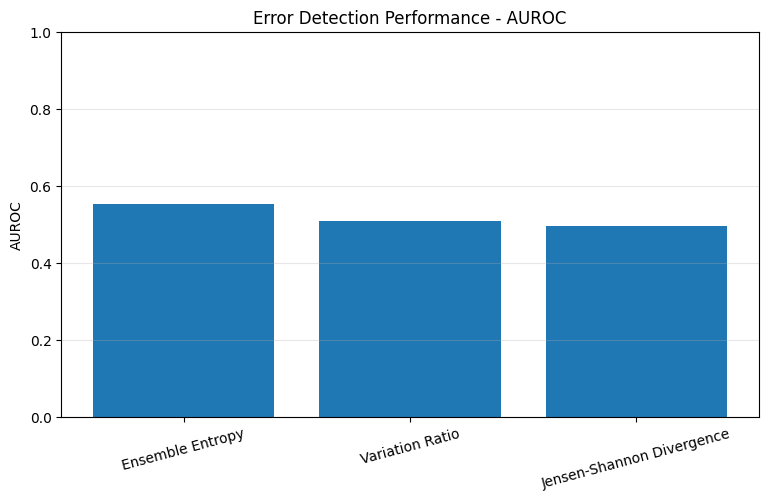

In [30]:
# Cell 30: Visualize AUROC Comparison

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Metric"],
    results_df["AUROC"]
)

plt.ylim(0, 1)
plt.ylabel("AUROC")
plt.title("Error Detection Performance - AUROC")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

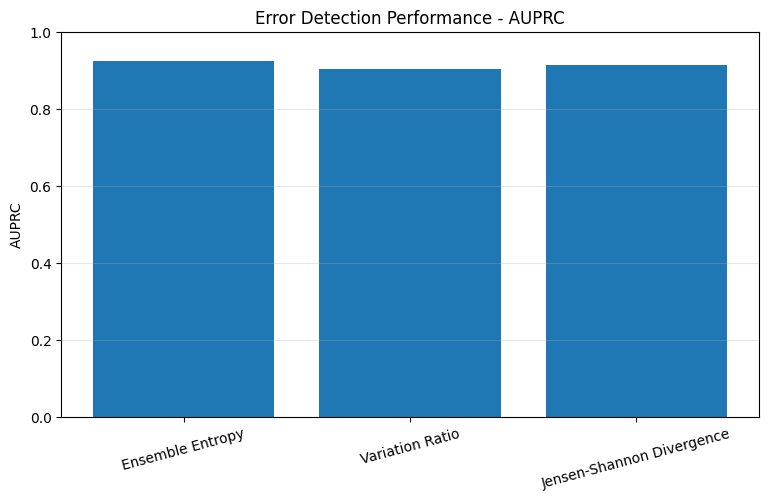

In [31]:
# Cell 31: Visualize AUPRC Comparison

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Metric"],
    results_df["AUPRC"]
)

plt.ylim(0, 1)
plt.ylabel("AUPRC")
plt.title("Error Detection Performance - AUPRC")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [32]:
# Cell 32: Calculate Ensemble Confidence

ensemble_confidence = np.max(
    ensemble_probabilities,
    axis=1
)

print("Confidence shape:", ensemble_confidence.shape)
print("First 10 confidence values:")
print(ensemble_confidence[:10])

Confidence shape: (1000,)
First 10 confidence values:
[0.14356812 0.14159757 0.16347851 0.146407   0.15540973 0.1234981
 0.12919117 0.1359049  0.1598293  0.19251843]


In [33]:
# Cell 33: Verify Confidence and Correctness

calibration_data = pd.DataFrame({
    "Confidence": ensemble_confidence,
    "Correct": ensemble_correctness.astype(int)
})

print(calibration_data.head(10))

   Confidence  Correct
0    0.143568        0
1    0.141598        0
2    0.163479        0
3    0.146407        0
4    0.155410        0
5    0.123498        0
6    0.129191        0
7    0.135905        0
8    0.159829        0
9    0.192518        0


In [34]:
# Cell 34: Calculate Expected Calibration Error

def calculate_ece(confidence, correctness, num_bins=15):

    bin_boundaries = np.linspace(0, 1, num_bins + 1)

    ece = 0

    for i in range(num_bins):

        lower_bound = bin_boundaries[i]
        upper_bound = bin_boundaries[i + 1]

        if i == num_bins - 1:
            mask = (
                (confidence >= lower_bound) &
                (confidence <= upper_bound)
            )
        else:
            mask = (
                (confidence >= lower_bound) &
                (confidence < upper_bound)
            )

        if np.sum(mask) == 0:
            continue

        bin_accuracy = np.mean(correctness[mask])
        bin_confidence = np.mean(confidence[mask])

        bin_weight = np.sum(mask) / len(confidence)

        ece += bin_weight * abs(
            bin_accuracy - bin_confidence
        )

    return ece

In [35]:
# Cell 35: Evaluate Ensemble Calibration

ece_score = calculate_ece(
    ensemble_confidence,
    ensemble_correctness
)

print("Expected Calibration Error:", ece_score)

Expected Calibration Error: 0.057851933877776256


In [38]:
# Cell 36: Unit Test for ECE

assert np.isclose(test_ece, 0.05)

print("All tests passed!")

All tests passed!


In [39]:
# Cell 37: Calculate Reliability Diagram Values

def get_calibration_data(confidence, correctness, num_bins=15):

    bin_boundaries = np.linspace(0, 1, num_bins + 1)

    bin_confidences = []
    bin_accuracies = []
    bin_counts = []

    for i in range(num_bins):

        lower = bin_boundaries[i]
        upper = bin_boundaries[i + 1]

        if i == num_bins - 1:
            mask = (
                (confidence >= lower) &
                (confidence <= upper)
            )
        else:
            mask = (
                (confidence >= lower) &
                (confidence < upper)
            )

        if np.sum(mask) == 0:
            continue

        bin_confidences.append(np.mean(confidence[mask]))
        bin_accuracies.append(np.mean(correctness[mask]))
        bin_counts.append(np.sum(mask))

    return (
        np.array(bin_confidences),
        np.array(bin_accuracies),
        np.array(bin_counts)
    )

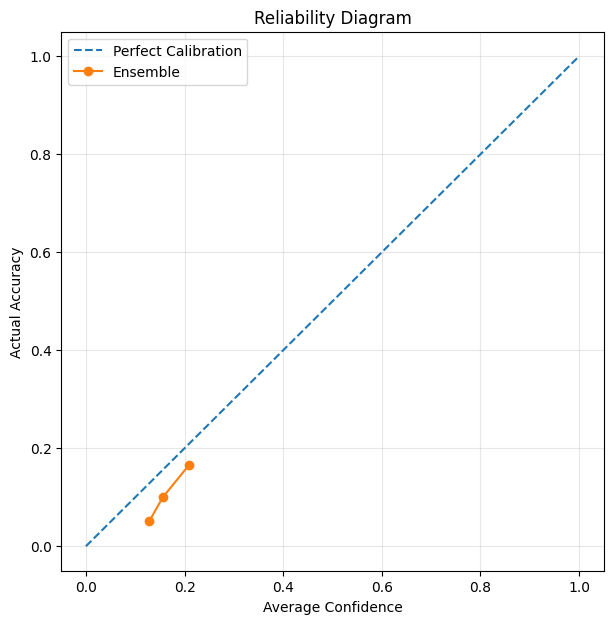

In [45]:
# Cell 38: Visualize Reliability Diagram

bin_confidences, bin_accuracies, bin_counts = get_calibration_data(
    ensemble_confidence,
    ensemble_correctness
)

plt.figure(figsize=(7, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    bin_confidences,
    bin_accuracies,
    marker="o",
    label="Ensemble"
)

plt.xlabel("Average Confidence")
plt.ylabel("Actual Accuracy")
plt.title("Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [46]:
# Cell 39: Generate Calibration Results Table

calibration_results = pd.DataFrame({
    "Metric": ["Expected Calibration Error"],
    "Value": [ece_score]
})

print(calibration_results)

                       Metric     Value
0  Expected Calibration Error  0.057852


In [47]:
# Cell 40: Calculate Risk-Coverage Curve

def calculate_risk_coverage(uncertainty_scores, correctness):

    sorted_indices = np.argsort(uncertainty_scores)

    sorted_correctness = correctness[sorted_indices]

    total_samples = len(correctness)

    cumulative_errors = np.cumsum(
        ~sorted_correctness
    )

    retained_samples = np.arange(1, total_samples + 1)

    coverage = retained_samples / total_samples

    risk = cumulative_errors / retained_samples

    return coverage, risk


In [48]:
# Cell 41: Evaluate Risk-Coverage for All Metrics

risk_coverage_results = {}

for metric, scores in uncertainty_scores.items():

    coverage, risk = calculate_risk_coverage(
        scores,
        ensemble_correctness
    )

    risk_coverage_results[metric] = {
        "Coverage": coverage,
        "Risk": risk
    }

    print(metric)
    print("Final coverage:", coverage[-1])
    print("Final risk:", risk[-1])
    print()

Ensemble Entropy
Final coverage: 1.0
Final risk: 0.904

Variation Ratio
Final coverage: 1.0
Final risk: 0.904

Jensen-Shannon Divergence
Final coverage: 1.0
Final risk: 0.904



In [49]:
# Cell 42: Calculate Area Under Risk-Coverage Curve

def calculate_aurc(coverage, risk):

    aurc = np.mean(risk)

    return aurc

In [50]:
# Cell 43: Compare AURC Across Uncertainty Metrics

aurc_results = []

for metric, values in risk_coverage_results.items():

    aurc = calculate_aurc(
        values["Coverage"],
        values["Risk"]
    )

    aurc_results.append({
        "Metric": metric,
        "AURC": aurc
    })

aurc_df = pd.DataFrame(aurc_results)

print(aurc_df)

                      Metric      AURC
0           Ensemble Entropy  0.891686
1            Variation Ratio  0.907905
2  Jensen-Shannon Divergence  0.916001


In [51]:
# Cell 44: Unit Test for Risk-Coverage and AURC

test_uncertainty = np.array([
    0.1, 0.2, 0.8, 0.9
])

test_correctness = np.array([
    True, True, False, False
])

test_coverage, test_risk = calculate_risk_coverage(
    test_uncertainty,
    test_correctness
)

test_aurc = calculate_aurc(
    test_coverage,
    test_risk
)

print("Coverage:", test_coverage)
print("Risk:", test_risk)
print("AURC:", test_aurc)

assert np.allclose(
    test_coverage,
    [0.25, 0.50, 0.75, 1.00]
)

assert np.allclose(
    test_risk,
    [0.0, 0.0, 1/3, 0.5]
)

assert np.isclose(test_aurc, 5/24)

print("All tests passed!")

Coverage: [0.25 0.5  0.75 1.  ]
Risk: [0.         0.         0.33333333 0.5       ]
AURC: 0.20833333333333331
All tests passed!


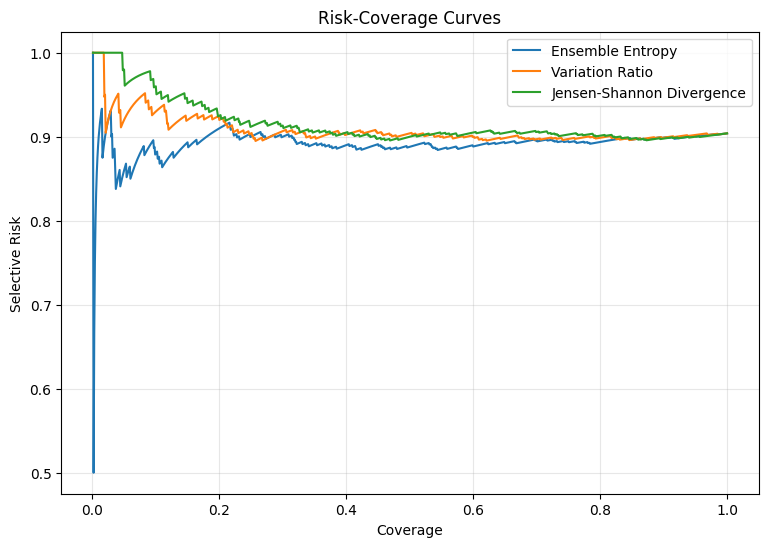

In [52]:
# Cell 45: Visualize Risk-Coverage Curves

plt.figure(figsize=(9, 6))

for metric, values in risk_coverage_results.items():

    plt.plot(
        values["Coverage"],
        values["Risk"],
        label=metric
    )

plt.xlabel("Coverage")
plt.ylabel("Selective Risk")
plt.title("Risk-Coverage Curves")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

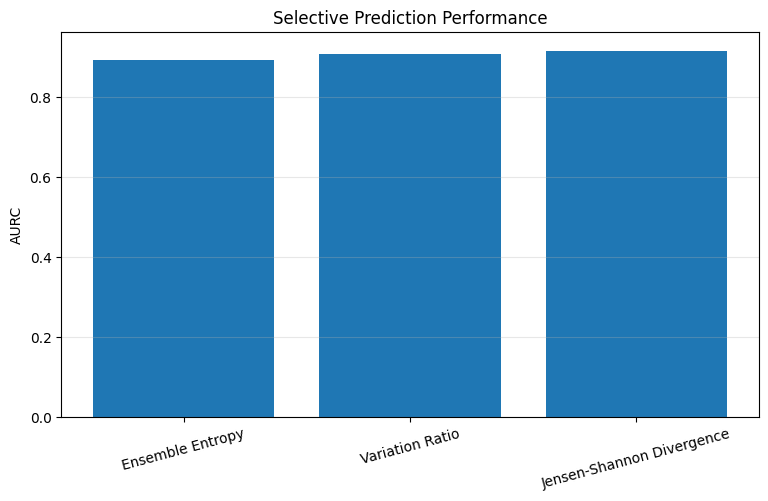

In [53]:
# Cell 46: Visualize AURC Comparison

plt.figure(figsize=(9, 5))

plt.bar(
    aurc_df["Metric"],
    aurc_df["AURC"]
)

plt.ylabel("AURC")
plt.title("Selective Prediction Performance")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [54]:
# Cell 47: Import Image Processing Utilities

import torchvision.transforms.functional as TF
import torch.nn.functional as F

print("Image processing utilities imported successfully.")

Image processing utilities imported successfully.


In [55]:
# Cell 48: Define Corruption Severity Parameters

SEVERITY_LEVELS = [1, 2, 3, 4, 5]

NOISE_LEVELS = {
    1: 0.05,
    2: 0.10,
    3: 0.15,
    4: 0.20,
    5: 0.25
}

BLUR_LEVELS = {
    1: (3, 0.5),
    2: (5, 1.0),
    3: (7, 1.5),
    4: (9, 2.0),
    5: (11, 2.5)
}

ROTATION_LEVELS = {
    1: 5,
    2: 10,
    3: 15,
    4: 20,
    5: 25
}

print("Corruption severity configurations initialized.")

Corruption severity configurations initialized.


In [56]:
# Cell 49: Apply Gaussian Noise

def apply_gaussian_noise(images, severity):

    noise_std = NOISE_LEVELS[severity]

    noise = torch.randn_like(images) * noise_std

    corrupted_images = images + noise

    return torch.clamp(corrupted_images, 0, 1)

In [57]:
# Cell 50: Apply Gaussian Blur

def apply_gaussian_blur(images, severity):

    kernel_size, sigma = BLUR_LEVELS[severity]

    corrupted_images = []

    for image in images:

        blurred_image = TF.gaussian_blur(
            image,
            kernel_size=kernel_size,
            sigma=sigma
        )

        corrupted_images.append(blurred_image)

    return torch.stack(corrupted_images)

In [58]:
# Cell 51: Apply Image Rotation

def apply_rotation(images, severity):

    angle = ROTATION_LEVELS[severity]

    corrupted_images = []

    for image in images:

        rotated_image = TF.rotate(
            image,
            angle=angle,
            interpolation=TF.InterpolationMode.BILINEAR,
            fill=0
        )

        corrupted_images.append(rotated_image)

    return torch.stack(corrupted_images)

In [59]:
# Cell 52: Apply Selected Corruption

def apply_corruption(images, corruption_type, severity):

    if severity not in SEVERITY_LEVELS:
        raise ValueError("Severity must be between 1 and 5.")

    if corruption_type == "gaussian_noise":
        return apply_gaussian_noise(images, severity)

    elif corruption_type == "gaussian_blur":
        return apply_gaussian_blur(images, severity)

    elif corruption_type == "rotation":
        return apply_rotation(images, severity)

    else:
        raise ValueError("Unknown corruption type.")

In [60]:
# Cell 53: Generate Dummy CIFAR-10 Images

torch.manual_seed(42)

dummy_images = torch.rand(8, 3, 32, 32)

print("Dummy image shape:", dummy_images.shape)
print("Minimum pixel value:", dummy_images.min().item())
print("Maximum pixel value:", dummy_images.max().item())

Dummy image shape: torch.Size([8, 3, 32, 32])
Minimum pixel value: 2.205371856689453e-06
Maximum pixel value: 0.9999793171882629


In [61]:
# Cell 54: Test All Corruption Functions

corruption_types = [
    "gaussian_noise",
    "gaussian_blur",
    "rotation"
]

for corruption in corruption_types:

    corrupted_images = apply_corruption(
        dummy_images,
        corruption,
        severity=3
    )

    print(corruption)
    print("Shape:", corrupted_images.shape)
    print("Minimum:", corrupted_images.min().item())
    print("Maximum:", corrupted_images.max().item())

    assert corrupted_images.shape == dummy_images.shape
    assert torch.all(corrupted_images >= 0)
    assert torch.all(corrupted_images <= 1)

print("All corruption tests passed!")

gaussian_noise
Shape: torch.Size([8, 3, 32, 32])
Minimum: 0.0
Maximum: 1.0
gaussian_blur
Shape: torch.Size([8, 3, 32, 32])
Minimum: 0.28591683506965637
Maximum: 0.7422493100166321
rotation
Shape: torch.Size([8, 3, 32, 32])
Minimum: 0.0
Maximum: 0.9826554656028748
All corruption tests passed!


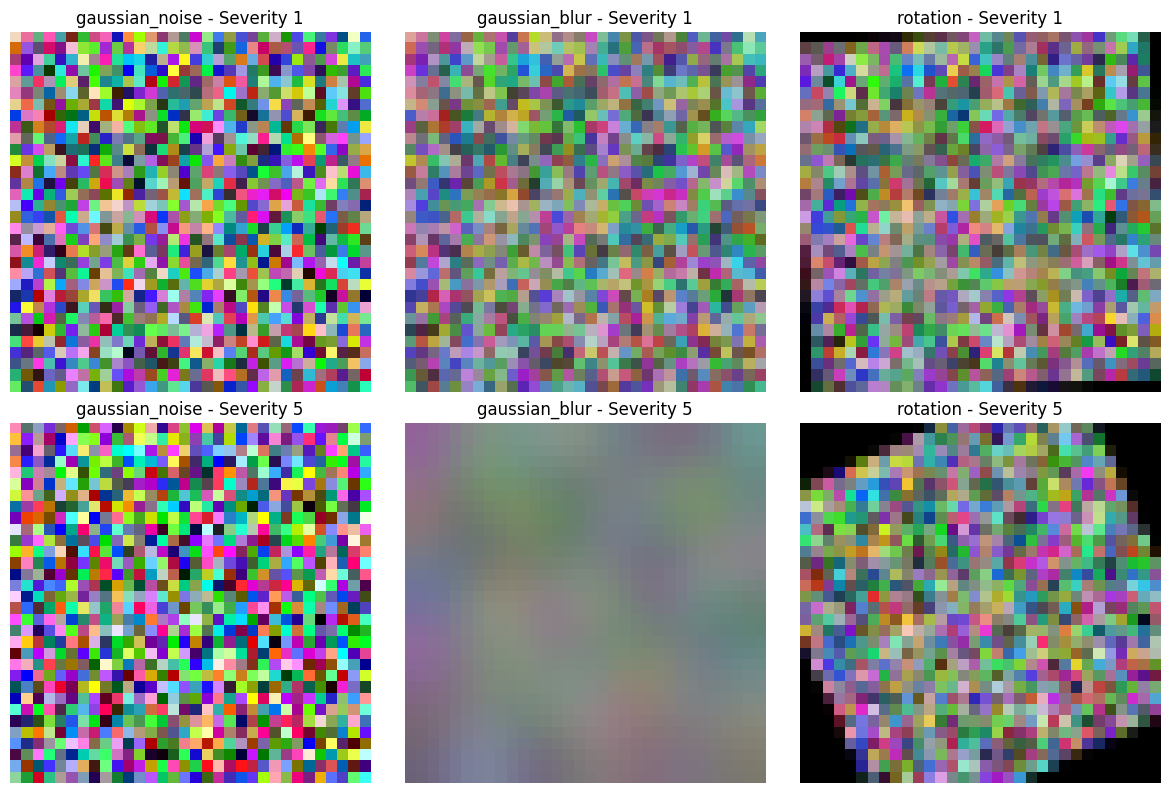

In [62]:
# Cell 55: Visualize Different Corruption Severities

original_image = dummy_images[0:1]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

corruption_types = [
    "gaussian_noise",
    "gaussian_blur",
    "rotation"
]

for column, corruption in enumerate(corruption_types):

    for row, severity in enumerate([1, 5]):

        corrupted_image = apply_corruption(
            original_image,
            corruption,
            severity
        )

        image = corrupted_image[0].permute(1, 2, 0).numpy()

        axes[row, column].imshow(image)
        axes[row, column].set_title(
            f"{corruption} - Severity {severity}"
        )

        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

In [63]:
# Cell 56: Generate Distribution Shift Configurations

experiment_configs = [
    {
        "corruption": corruption,
        "severity": severity
    }
    for corruption in corruption_types
    for severity in SEVERITY_LEVELS
]

print("Total corrupted conditions:", len(experiment_configs))

for config in experiment_configs:
    print(config)

Total corrupted conditions: 15
{'corruption': 'gaussian_noise', 'severity': 1}
{'corruption': 'gaussian_noise', 'severity': 2}
{'corruption': 'gaussian_noise', 'severity': 3}
{'corruption': 'gaussian_noise', 'severity': 4}
{'corruption': 'gaussian_noise', 'severity': 5}
{'corruption': 'gaussian_blur', 'severity': 1}
{'corruption': 'gaussian_blur', 'severity': 2}
{'corruption': 'gaussian_blur', 'severity': 3}
{'corruption': 'gaussian_blur', 'severity': 4}
{'corruption': 'gaussian_blur', 'severity': 5}
{'corruption': 'rotation', 'severity': 1}
{'corruption': 'rotation', 'severity': 2}
{'corruption': 'rotation', 'severity': 3}
{'corruption': 'rotation', 'severity': 4}
{'corruption': 'rotation', 'severity': 5}


In [64]:
# Cell 57: Complete Uncertainty Evaluation Module

def calculate_entropy(predictions):

    predictions = np.clip(predictions, 1e-12, 1.0)

    entropy = -np.sum(
        predictions * np.log(predictions),
        axis=-1
    )

    return entropy


def calculate_variation_ratio(predicted_classes):

    ensemble_size, num_samples = predicted_classes.shape

    variation_ratios = np.zeros(num_samples)

    for sample in range(num_samples):

        class_counts = np.bincount(
            predicted_classes[:, sample],
            minlength=NUM_CLASSES
        )

        maximum_votes = np.max(class_counts)

        variation_ratios[sample] = (
            1 - maximum_votes / ensemble_size
        )

    return variation_ratios


def calculate_jsd(predictions):

    predictions = np.clip(predictions, 1e-12, 1.0)

    mean_predictions = np.mean(
        predictions,
        axis=0
    )

    mean_predictions = np.clip(
        mean_predictions,
        1e-12,
        1.0
    )

    kl_divergence = np.sum(
        predictions * np.log(
            predictions / mean_predictions[np.newaxis, :, :]
        ),
        axis=2
    )

    jsd = np.mean(
        kl_divergence,
        axis=0
    )

    return jsd


def calculate_ece(confidence, correctness, num_bins=15):

    bin_boundaries = np.linspace(
        0,
        1,
        num_bins + 1
    )

    ece = 0.0

    for i in range(num_bins):

        lower = bin_boundaries[i]
        upper = bin_boundaries[i + 1]

        if i == num_bins - 1:

            mask = (
                (confidence >= lower) &
                (confidence <= upper)
            )

        else:

            mask = (
                (confidence >= lower) &
                (confidence < upper)
            )

        if np.sum(mask) == 0:
            continue

        bin_accuracy = np.mean(correctness[mask])
        bin_confidence = np.mean(confidence[mask])

        bin_weight = np.sum(mask) / len(confidence)

        ece += bin_weight * abs(
            bin_accuracy - bin_confidence
        )

    return ece


def calculate_risk_coverage(uncertainty_scores, correctness):

    sorted_indices = np.argsort(uncertainty_scores)

    sorted_correctness = correctness[sorted_indices]

    total_samples = len(correctness)

    cumulative_errors = np.cumsum(
        ~sorted_correctness
    )

    retained_samples = np.arange(
        1,
        total_samples + 1
    )

    coverage = retained_samples / total_samples

    risk = cumulative_errors / retained_samples

    return coverage, risk


def calculate_aurc(coverage, risk):

    return np.mean(risk)

In [70]:
# Cell 58: Main Ensemble Evaluation Function

def evaluate_ensemble(
    predictions,
    ground_truth,
    experiment_name="Clean",
    corruption="None",
    severity=0
):

    predictions = np.asarray(predictions)
    ground_truth = np.asarray(ground_truth)

    # Step 1: Validate input dimensions
    if predictions.ndim != 3:
        raise ValueError("Predictions must have shape (ensemble_size, num_samples, num_classes).")

    ensemble_size, num_samples, num_classes = predictions.shape

    if len(ground_truth) != num_samples:
        raise ValueError("Ground truth size must match number of samples.")

    if not np.all(np.isfinite(predictions)):
        raise ValueError("Predictions contain invalid values.")

    if not np.all(np.isfinite(ground_truth)):
        raise ValueError("Ground truth contains invalid values.")

    if np.any(predictions < 0) or np.any(predictions > 1):
        raise ValueError("Probabilities must be between 0 and 1.")

    if not np.allclose(predictions.sum(axis=2), 1.0, atol=1e-5):
        raise ValueError("Each probability distribution must sum to 1.")

    if np.any(ground_truth < 0) or np.any(ground_truth >= num_classes):
        raise ValueError("Invalid ground truth class labels.")

    # Step 2: Calculate ensemble probabilities
    ensemble_probabilities = np.mean(
        predictions,
        axis=0
    )

    # Step 3: Generate final predictions
    ensemble_predictions = np.argmax(
        ensemble_probabilities,
        axis=1
    )

    # Step 4: Calculate correctness and errors
    correctness = (
        ensemble_predictions == ground_truth
    )

    error_labels = (~correctness).astype(int)

    # Step 5: Calculate individual model accuracies
    individual_accuracies = []

    for model in range(ensemble_size):

        model_predictions = np.argmax(
            predictions[model],
            axis=1
        )

        model_accuracy = np.mean(
            model_predictions == ground_truth
        )

        individual_accuracies.append(model_accuracy)

    # Step 6: Calculate ensemble accuracy
    ensemble_accuracy = np.mean(correctness)

    # Step 7: Calculate ensemble confidence
    confidence = np.max(
        ensemble_probabilities,
        axis=1
    )

    # Step 8: Calculate predictive entropy
    entropy = calculate_entropy(
        ensemble_probabilities
    )

    # Step 9: Calculate ensemble disagreement
    predicted_classes = np.argmax(
        predictions,
        axis=2
    )

    variation_ratio = calculate_variation_ratio(
        predicted_classes
    )

    jsd_scores = calculate_jsd(
        predictions
    )

    # Step 10: Collect uncertainty scores
    uncertainty_scores = {
        "Ensemble Entropy": entropy,
        "Variation Ratio": variation_ratio,
        "Jensen-Shannon Divergence": jsd_scores
    }

    # Step 11: Calculate AUROC and AUPRC
    error_detection_results = {}

    for metric, scores in uncertainty_scores.items():

        if len(np.unique(error_labels)) == 2:

            auroc = roc_auc_score(
                error_labels,
                scores
            )

            auprc = average_precision_score(
                error_labels,
                scores
            )

        else:

            auroc = np.nan
            auprc = np.nan

        error_detection_results[metric] = {
            "AUROC": auroc,
            "AUPRC": auprc
        }

    # Step 12: Calculate ECE
    ece = calculate_ece(
        confidence,
        correctness
    )

    # Step 13: Calculate risk-coverage and AURC
    risk_coverage_results = {}
    aurc_results = {}

    for metric, scores in uncertainty_scores.items():

        coverage, risk = calculate_risk_coverage(
            scores,
            correctness
        )

        aurc = calculate_aurc(
            coverage,
            risk
        )

        risk_coverage_results[metric] = {
            "Coverage": coverage,
            "Risk": risk
        }

        aurc_results[metric] = aurc

    # Step 14: Generate experiment summary
    summary = {
        "Experiment": experiment_name,
        "Corruption": corruption,
        "Severity": severity,
        "Ensemble Accuracy": ensemble_accuracy,
        "ECE": ece
    }

    for model in range(ensemble_size):

        summary[f"Model {model + 1} Accuracy"] = (
            individual_accuracies[model]
        )

    for metric in uncertainty_scores:

        summary[f"{metric} AUROC"] = (
            error_detection_results[metric]["AUROC"]
        )

        summary[f"{metric} AUPRC"] = (
            error_detection_results[metric]["AUPRC"]
        )

        summary[f"{metric} AURC"] = (
            aurc_results[metric]
        )

    # Step 15: Generate sample-level results
    sample_results = pd.DataFrame({

        "Ground Truth": ground_truth,

        "Predicted Class": ensemble_predictions,

        "Correct": correctness,

        "Error": error_labels,

        "Confidence": confidence,

        "Ensemble Entropy": entropy,

        "Variation Ratio": variation_ratio,

        "Jensen-Shannon Divergence": jsd_scores

    })

    # Step 16: Return all evaluation results
    return {
        "Summary": summary,
        "Sample Results": sample_results,
        "Uncertainty Scores": uncertainty_scores,
        "Risk Coverage": risk_coverage_results,
        "Error Detection": error_detection_results,
        "Ensemble Probabilities": ensemble_probabilities
    }

In [72]:
# Cell 59: Run Complete Ensemble Evaluation

clean_results = evaluate_ensemble(
    predictions=synthetic_predictions,
    ground_truth=ground_truth,
    experiment_name="Clean Synthetic",
    corruption="None",
    severity=0
)

print("Evaluation completed!")
print("Result type:", type(clean_results))

Evaluation completed!
Result type: <class 'dict'>


In [73]:
# Cell 60: Display Experiment Summary

print("\n========== EPIAWARE EXPERIMENT SUMMARY ==========\n")

for metric, value in clean_results["Summary"].items():

    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")

    else:
        print(f"{metric}: {value}")

print("\n=================================================")


========== EPIAWARE EXPERIMENT SUMMARY ==========

Experiment: Clean Synthetic
Corruption: None
Severity: 0
Ensemble Accuracy: 0.0960
ECE: 0.0579
Model 1 Accuracy: 0.1050
Model 2 Accuracy: 0.1040
Model 3 Accuracy: 0.0930
Ensemble Entropy AUROC: 0.5549
Ensemble Entropy AUPRC: 0.9248
Ensemble Entropy AURC: 0.8917
Variation Ratio AUROC: 0.5088
Variation Ratio AUPRC: 0.9055
Variation Ratio AURC: 0.9079
Jensen-Shannon Divergence AUROC: 0.4969
Jensen-Shannon Divergence AUPRC: 0.9148
Jensen-Shannon Divergence AURC: 0.9160



In [74]:
# Cell 61: Generate Individual Sample Results Table

sample_results_df = clean_results["Sample Results"].copy()

print("Total evaluated samples:", len(sample_results_df))

print("\nFirst 15 evaluated samples:")

display(sample_results_df.head(15))

print("\nDataset statistics:")

display(sample_results_df.describe())

Total evaluated samples: 1000

First 15 evaluated samples:


,Ground Truth,Predicted Class,Correct,Error,Confidence,Ensemble Entropy,Variation Ratio,Jensen-Shannon Divergence
0,6,5,False,1,0.143568,2.245519,0.333333,0.126177
1,3,4,False,1,0.141598,2.236735,0.666667,0.219252
2,7,5,False,1,0.163479,2.213583,0.333333,0.125881
3,4,2,False,1,0.146407,2.223071,0.333333,0.129019
4,6,9,False,1,0.155410,2.244232,0.333333,0.118694
5,9,5,False,1,0.123498,2.287951,0.666667,0.123166
6,2,3,False,1,0.129191,2.273591,0.666667,0.059638
7,6,8,False,1,0.135905,2.281001,0.333333,0.125408
8,7,1,False,1,0.159829,2.240149,0.333333,0.060385
9,4,2,False,1,0.192518,2.199550,0.666667,0.128657



Dataset statistics:


,Ground Truth,Predicted Class,Error,Confidence,Ensemble Entropy,Variation Ratio,Jensen-Shannon Divergence
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,4.448000,4.473000,0.904000,0.153852,2.245204,0.573333,0.128324
std,2.912005,2.967504,0.294739,0.017421,0.027363,0.154133,0.040564
min,0.000000,0.000000,0.000000,0.116717,2.108149,0.000000,0.028535
25%,2.000000,2.000000,1.000000,0.141254,2.228315,0.333333,0.099206
50%,4.000000,4.000000,1.000000,0.151593,2.249748,0.666667,0.124879
75%,7.000000,7.000000,1.000000,0.164474,2.266321,0.666667,0.154452
max,9.000000,9.000000,1.000000,0.217603,2.294768,0.666667,0.272715


In [75]:
# Cell 62: Identify High-Confidence Incorrect Predictions

incorrect_samples = sample_results_df[
    sample_results_df["Correct"] == False
].copy()

high_confidence_errors = incorrect_samples[
    incorrect_samples["Confidence"] >= 0.80
].sort_values(
    by="Confidence",
    ascending=False
)

print("Total samples:", len(sample_results_df))

print(
    "Total incorrect predictions:",
    len(incorrect_samples)
)

print(
    "High-confidence incorrect predictions:",
    len(high_confidence_errors)
)

print("\nHigh-confidence error examples:")

display(high_confidence_errors.head(20))

Total samples: 1000
Total incorrect predictions: 904
High-confidence incorrect predictions: 0

High-confidence error examples:


,Ground Truth,Predicted Class,Correct,Error,Confidence,Ensemble Entropy,Variation Ratio,Jensen-Shannon Divergence


In [76]:
# Cell 63: Initialize Experiment Results Storage

all_experiment_results = []

def store_experiment_results(evaluation_results):

    if evaluation_results is None:
        raise ValueError("Evaluation results cannot be None.")

    if "Summary" not in evaluation_results:
        raise ValueError("Summary is missing from evaluation results.")

    experiment_summary = evaluation_results["Summary"]

    all_experiment_results.append(
        experiment_summary.copy()
    )

    print(
        "Successfully stored:",
        experiment_summary["Experiment"]
    )


store_experiment_results(clean_results)

print("\nTotal experiments stored:", len(all_experiment_results))

Successfully stored: Clean Synthetic

Total experiments stored: 1


In [77]:
# Cell 64: Generate Combined Experiment Results Table

def generate_experiment_table(results):

    if len(results) == 0:
        return pd.DataFrame()

    results_table = pd.DataFrame(results)

    results_table = results_table.sort_values(
        by=["Corruption", "Severity"]
    ).reset_index(drop=True)

    return results_table


combined_results_df = generate_experiment_table(
    all_experiment_results
)

print("Combined experiment results:")

display(combined_results_df)

Combined experiment results:


,Experiment,Corruption,Severity,Ensemble Accuracy,ECE,Model 1 Accuracy,Model 2 Accuracy,Model 3 Accuracy,Ensemble Entropy AUROC,Ensemble Entropy AUPRC,Ensemble Entropy AURC,Variation Ratio AUROC,Variation Ratio AUPRC,Variation Ratio AURC,Jensen-Shannon Divergence AUROC,Jensen-Shannon Divergence AUPRC,Jensen-Shannon Divergence AURC
0,Clean Synthetic,None,0,0.096,0.057852,0.105,0.104,0.093,0.55486,0.92482,0.891686,0.508803,0.905547,0.907905,0.496854,0.914801,0.916001


In [78]:
# Cell 65: Export Experimental Results to CSV

combined_results_df.to_csv(
    "epiaware_experiment_results.csv",
    index=False
)

sample_results_df.to_csv(
    "epiaware_sample_results.csv",
    index=False
)

print("Files exported successfully!")

print("\nGenerated files:")
print("1. epiaware_experiment_results.csv")
print("2. epiaware_sample_results.csv")

Files exported successfully!

Generated files:
1. epiaware_experiment_results.csv
2. epiaware_sample_results.csv


In [79]:
# Cell 66: Download Experimental CSV Files

from google.colab import files

files.download("epiaware_experiment_results.csv")

files.download("epiaware_sample_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [80]:
# Cell 67: Validate Complete Evaluation Pipeline

# Check ensemble probabilities
assert clean_results["Ensemble Probabilities"].shape == (
    NUM_SAMPLES,
    NUM_CLASSES
)

# Check sample-level results
assert len(clean_results["Sample Results"]) == NUM_SAMPLES

# Check uncertainty metrics
assert len(clean_results["Uncertainty Scores"]) == 3

# Check risk-coverage results
assert len(clean_results["Risk Coverage"]) == 3

# Check error detection results
assert len(clean_results["Error Detection"]) == 3

# Check ensemble accuracy
assert 0 <= clean_results["Summary"]["Ensemble Accuracy"] <= 1

# Check ECE
assert 0 <= clean_results["Summary"]["ECE"] <= 1

# Check uncertainty score lengths
for metric, scores in clean_results["Uncertainty Scores"].items():

    assert len(scores) == NUM_SAMPLES

# Check risk-coverage arrays
for metric, values in clean_results["Risk Coverage"].items():

    assert len(values["Coverage"]) == NUM_SAMPLES

    assert len(values["Risk"]) == NUM_SAMPLES

# Check coverage boundaries
for metric, values in clean_results["Risk Coverage"].items():

    assert np.isclose(values["Coverage"][0], 1 / NUM_SAMPLES)

    assert np.isclose(values["Coverage"][-1], 1.0)

# Check exported result table
assert len(combined_results_df) == 1

print("======================================")
print("EPIAWARE PIPELINE VALIDATION")
print("======================================")

print("Ensemble probabilities: PASSED")
print("Sample-level results: PASSED")
print("Uncertainty metrics: PASSED")
print("Error detection metrics: PASSED")
print("Calibration metrics: PASSED")
print("Risk-coverage metrics: PASSED")
print("Experiment storage: PASSED")
print("Result table generation: PASSED")

print("======================================")
print("ALL VALIDATION TESTS PASSED!")
print("======================================")

EPIAWARE PIPELINE VALIDATION
Ensemble probabilities: PASSED
Sample-level results: PASSED
Uncertainty metrics: PASSED
Error detection metrics: PASSED
Calibration metrics: PASSED
Risk-coverage metrics: PASSED
Experiment storage: PASSED
Result table generation: PASSED
ALL VALIDATION TESTS PASSED!
